In [ ]:
# WEEK 12: SPECTRAL CLUSTERING, DBSCAN AND GMM


In [ ]:
# PART 1: IMPORT LIBRARIES
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons, make_circles, load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import SpectralClustering, DBSCAN, KMeans
from sklearn.mixture import GaussianMixture

from sklearn.metrics import silhouette_score
print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# PART 2: UNDERSTANDING CLUSTERING
# ============================================================

# Create simple sample data
X, y = make_moons(n_samples=200, noise=0.05, random_state=42)
X
y

array([0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0,
       1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0,
       1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1,
       0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0,
       1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1,
       1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0,
       0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0,
       0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1,
       1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0,
       1, 1])

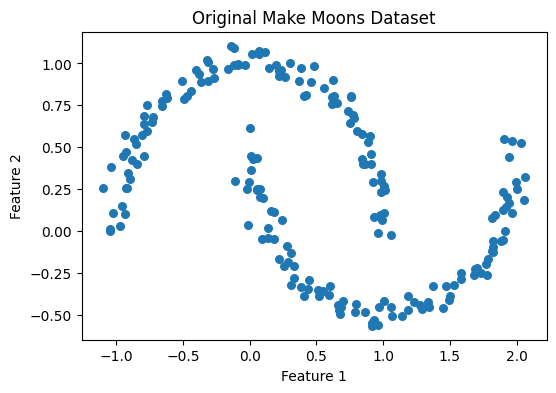

Dataset shape: (200, 2)


In [ ]:
# Display original data
plt.figure(figsize=(6, 4))
plt.scatter(X[:, 0], X[:, 1], s=30)
plt.title("Original Make Moons Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()
print("Dataset shape:", X.shape)

In [ ]:
# PART 3: SPECTRAL CLUSTERING
# ============================================================
# Step 1: Generate data
X, y = make_moons(n_samples=200, noise=0.05, random_state=42)

# Step 2: Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
# Step 3: Apply K-Means
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)
kmeans_labels

array([1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1,
       0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1,
       0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1,
       0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1,
       1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0,
       0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0,
       0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1,
       0, 1], dtype=int32)

In [ ]:
# Step 4: Apply Spectral Clustering
spectral = SpectralClustering(
    n_clusters=2,
    affinity="rbf",
    gamma=0.5,
    random_state=42
)

spectral_labels = spectral.fit_predict(X_scaled)
spectral_labels

array([0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0,
       1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0,
       1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0,
       1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1,
       1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0,
       0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1,
       1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1,
       1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0,
       1, 0], dtype=int32)

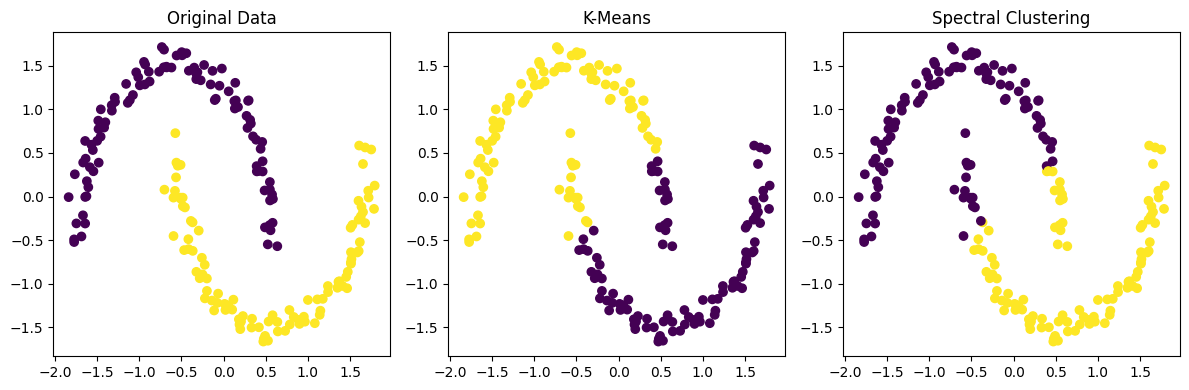

In [ ]:
# Step 5: Visualize both methods
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y)
plt.title("Original Data")

plt.subplot(1, 3, 2)
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=kmeans_labels)
plt.title("K-Means")

plt.subplot(1, 3, 3)
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=spectral_labels)
plt.title("Spectral Clustering")

plt.tight_layout()
plt.show()

In [ ]:
# Compare silhouette scores
print("K-Means Score:",
      round(silhouette_score(X_scaled, kmeans_labels), 3))
print("Spectral Score:",
      round(silhouette_score(X_scaled, spectral_labels), 3))

K-Means Score: 0.493
Spectral Score: 0.492


Similarity Matrix Shape: (200, 200)


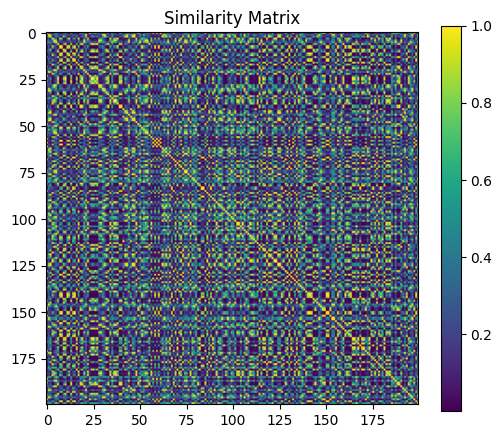

In [ ]:
# PART 4: UNDERSTANDING SIMILARITY MATRIX
# ============================================================
# Calculate similarity between data points
from sklearn.metrics.pairwise import rbf_kernel

W = rbf_kernel(X_scaled, gamma=0.5)
print("Similarity Matrix Shape:", W.shape)

# Display similarity matrix
plt.figure(figsize=(6, 5))
plt.imshow(W, cmap="viridis")
plt.colorbar()
plt.title("Similarity Matrix")
plt.show()

Laplacian Matrix Shape: (200, 200)


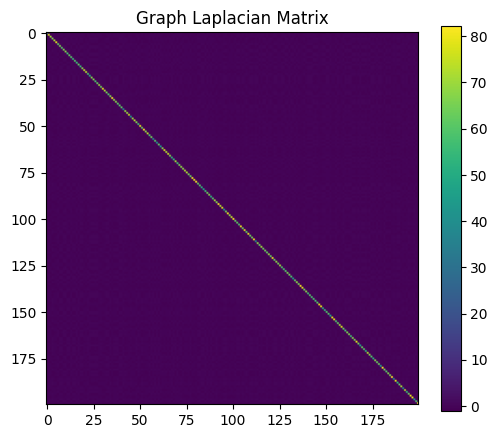

In [ ]:
# Create degree matrix
D = np.diag(np.sum(W, axis=1))
# Calculate Laplacian matrix
L = D - W
print("Laplacian Matrix Shape:", L.shape)

plt.figure(figsize=(6, 5))
plt.imshow(L, cmap="viridis")
plt.colorbar()
plt.title("Graph Laplacian Matrix")
plt.show()

In [ ]:
# Find eigenvalues
eigenvalues = np.linalg.eigvalsh(L)
print("First 10 Eigenvalues:")
print(np.round(eigenvalues[:10], 3))

First 10 Eigenvalues:
[-0.    15.597 30.409 33.962 37.699 37.981 39.391 39.795 41.331 41.761]


In [ ]:
# PART 5: DBSCAN CLUSTERING
# Generate circular data
X, y = make_circles(
    n_samples=300,
    factor=0.5,
    noise=0.05,
    random_state=42
)
X, y

(array([[-0.24183046,  0.42516296],
        [ 0.20976262, -0.48994789],
        [ 0.42792617,  0.04011244],
        [ 0.8816257 ,  0.41698355],
        [-0.47008918, -0.17129691],
        [-0.50576803,  0.01607921],
        [-0.19690914,  0.50749348],
        [-0.09380447, -1.00637942],
        [ 0.93184527,  0.18226342],
        [ 0.28550546,  0.43763665],
        [-0.40664959, -0.15272996],
        [-0.71742094,  0.64410026],
        [-0.42578857,  0.14708394],
        [-0.26539464,  1.00436644],
        [ 0.06622503,  0.55588968],
        [-0.44774192,  0.05318915],
        [ 0.46307834, -0.20945722],
        [-0.41526403,  0.32029147],
        [ 1.06836068, -0.08331252],
        [ 0.47105256,  0.34330276],
        [-0.98049989, -0.11652419],
        [-0.03668585, -1.0748191 ],
        [-0.25966226, -0.46496041],
        [-0.25198181, -0.45974584],
        [-0.43799687, -0.91941676],
        [-0.2081079 ,  0.98629719],
        [ 0.30517566, -0.3739772 ],
        [ 0.56709281, -0.097

In [ ]:
# Standardize the data
X_scaled = StandardScaler().fit_transform(X)
X_scaled

array([[-4.34359390e-01,  7.50485885e-01],
       [ 3.75379545e-01, -8.77075966e-01],
       [ 7.66562499e-01,  6.56578832e-02],
       [ 1.58007846e+00,  7.35938478e-01],
       [-8.43643728e-01, -3.10342244e-01],
       [-9.07618482e-01,  2.29138160e-02],
       [-3.53812220e-01,  8.96914070e-01],
       [-1.68938126e-01, -1.79557042e+00],
       [ 1.67012576e+00,  3.18479190e-01],
       [ 5.11191914e-01,  7.72670843e-01],
       [-7.29891974e-01, -2.77320168e-01],
       [-1.28712740e+00,  1.13987478e+00],
       [-7.64209545e-01,  2.55911049e-01],
       [-4.76611659e-01,  1.78062282e+00],
       [ 1.18006299e-01,  9.82988674e-01],
       [-8.03573478e-01,  8.89153539e-02],
       [ 8.29592873e-01, -3.78211890e-01],
       [-7.45338280e-01,  5.63967686e-01],
       [ 1.91490772e+00, -1.53858431e-01],
       [ 8.43891237e-01,  6.04894187e-01],
       [-1.75884691e+00, -2.12926723e-01],
       [-6.65203221e-02, -1.91729318e+00],
       [-4.66333090e-01, -8.32634705e-01],
       [-4.

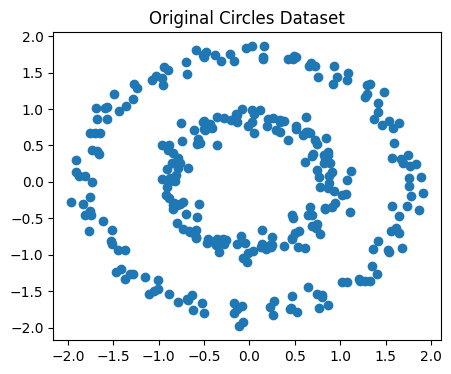

In [ ]:
# Visualize original data-Example-Ex MRI/CT Image Segmentation
plt.figure(figsize=(5, 4))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1])
plt.title("Original Circles Dataset")
plt.show()


In [ ]:
# Apply DBSCAN
dbscan = DBSCAN(eps=0.3, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)
dbscan_labels

array([0, 0, 0, 1, 0, 0, 0, 2, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 2,
       0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 0, 0, 2, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1,
       1, 0, 1, 0, 2, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1,
       1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 2,
       0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
       0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0,
       1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0,
       1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1,
       1, 0, 0, 0, 1, 0, 2, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0,
       0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1,
       1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0,
       1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1])

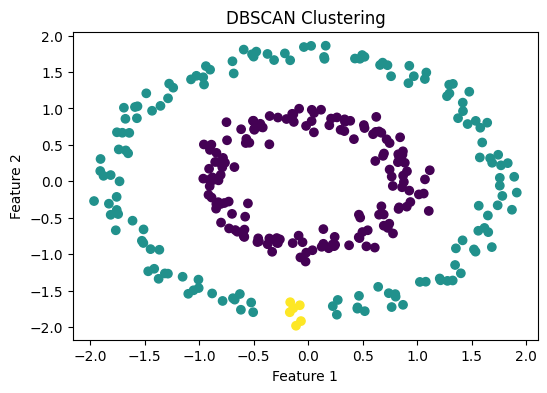

In [ ]:
# Display clusters
plt.figure(figsize=(6, 4))
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=dbscan_labels,
    cmap="viridis"
)

plt.title("DBSCAN Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()



In [ ]:
# Count clusters and noise
unique_labels = set(dbscan_labels)

print("Cluster Labels:", unique_labels)
print("Number of Clusters:",
      len(unique_labels - {-1}))
print("Noise Points:",
      np.sum(dbscan_labels == -1))

Cluster Labels: {np.int64(0), np.int64(1), np.int64(2)}
Number of Clusters: 3
Noise Points: 0



Epsilon: 0.1
Clusters: 10
Noise Points: 238


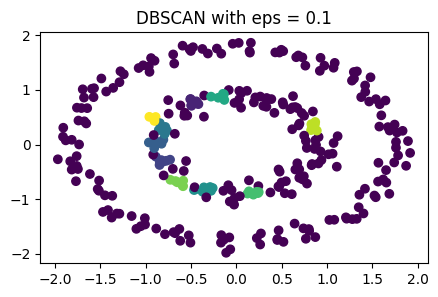


Epsilon: 0.2
Clusters: 18
Noise Points: 29


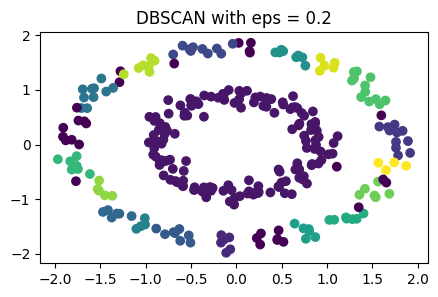


Epsilon: 0.3
Clusters: 3
Noise Points: 0


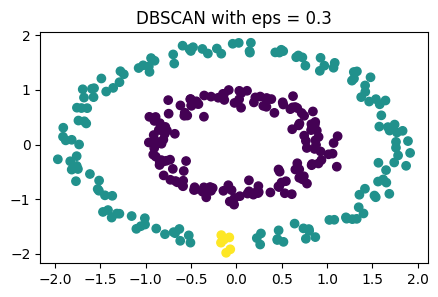


Epsilon: 0.5
Clusters: 1
Noise Points: 0


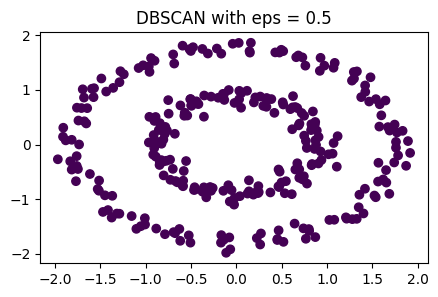

In [ ]:
# ============================================================
# PART 6: DBSCAN PARAMETER TUNING
# ============================================================

# Try different epsilon values
eps_values = [0.1, 0.2, 0.3, 0.5]
for eps in eps_values:

    model = DBSCAN(eps=eps, min_samples=5)

    labels = model.fit_predict(X_scaled)

    clusters = len(set(labels) - {-1})
    noise = np.sum(labels == -1)

    print("\nEpsilon:", eps)
    print("Clusters:", clusters)
    print("Noise Points:", noise)

    plt.figure(figsize=(5, 3))
    plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels)
    plt.title("DBSCAN with eps = " + str(eps))
    plt.show()




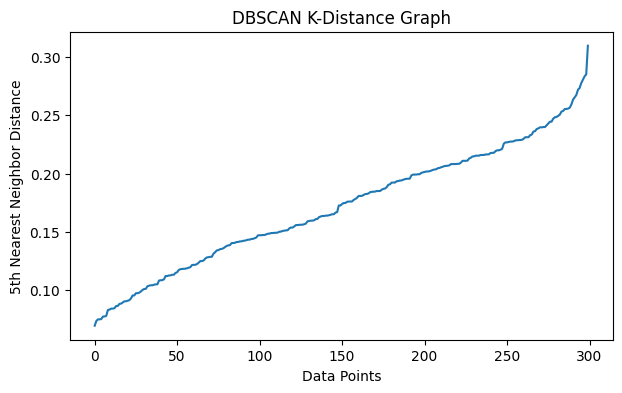

Use the elbow of the graph to help choose epsilon.


In [ ]:
# ============================================================
# PART 7: K-DISTANCE GRAPH
# ============================================================
from sklearn.neighbors import NearestNeighbors

# Find distance to the 5th nearest neighbor
neighbors = NearestNeighbors(n_neighbors=5)

neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Sort distances
k_distances = np.sort(distances[:, 4])

# Plot k-distance graph
plt.figure(figsize=(7, 4))

plt.plot(k_distances)

plt.xlabel("Data Points")
plt.ylabel("5th Nearest Neighbor Distance")

plt.title("DBSCAN K-Distance Graph")
plt.show()

print("Use the elbow of the graph to help choose epsilon.")




# GMM Model on IRIS Data

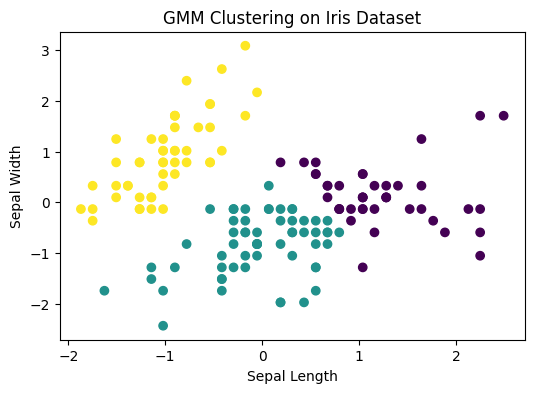

GMM Cluster Labels:
[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]


In [ ]:
# PART 8: GAUSSIAN MIXTURE MODEL (GMM)
# ============================================================

# Load Iris dataset
iris = load_iris()

# Take first two features
X = iris.data[:, :2]

# Standardize data
X_scaled = StandardScaler().fit_transform(X)

# Build GMM model
gmm = GaussianMixture(
    n_components=3,
    covariance_type="full",
    max_iter=300,
    reg_covar=1e-6,
    random_state=42
)

# Train model
gmm.fit(X_scaled)

# Predict cluster labels
gmm_labels = gmm.predict(X_scaled)

# Display clusters
plt.figure(figsize=(6, 4))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=gmm_labels,
    cmap="viridis"
)

plt.title("GMM Clustering on Iris Dataset")
plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.show()

print("GMM Cluster Labels:")
print(gmm_labels[:20])


In [ ]:
# ============================================================
# PART 9: GMM SOFT CLUSTERING
# ============================================================

# Calculate probability of belonging to each cluster
probabilities = gmm.predict_proba(X_scaled)

print("First 5 Probability Predictions:")
print(np.round(probabilities[:5], 3))

# Find the most uncertain observations
# Lower maximum probability means greater uncertainty
uncertainty = np.max(probabilities, axis=1)

most_uncertain = np.argsort(uncertainty)[:5]

print("\nMost Uncertain Observations:")
print(most_uncertain)

print("\nTheir Cluster Probabilities:")
print(np.round(probabilities[most_uncertain], 3))

First 5 Probability Predictions:
[[0.001 0.    0.999]
 [0.016 0.033 0.951]
 [0.001 0.    0.999]
 [0.001 0.001 0.998]
 [0.    0.    1.   ]]

Most Uncertain Observations:
[ 70  54  74 137 104]

Their Cluster Probabilities:
[[0.498 0.502 0.   ]
 [0.492 0.508 0.   ]
 [0.461 0.539 0.   ]
 [0.557 0.443 0.   ]
 [0.56  0.44  0.   ]]


In [ ]:
# ============================================================
# PART 10: GMM EM CONVERGENCE
# ============================================================
# Train GMM again and store likelihood at each iteration
gmm = GaussianMixture(
    n_components=3,
    max_iter=300,
    tol=1e-4,
    reg_covar=1e-6,
    random_state=42
)
gmm.fit(X_scaled)
print("Number of EM Iterations:", gmm.n_iter_)
print("Converged:", gmm.converged_)
print("Final Log Likelihood:", gmm.lower_bound_)


Number of EM Iterations: 31
Converged: True
Final Log Likelihood: -2.5093234168317995


/usr/local/lib/python3.13/dist-packages/sklearn/mixture/_base.py:269: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/mixture/_base.py:269: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/mixture/_base.py:269: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/mixture/_base.py:269: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(
/usr/local/lib/python3.1

Converged in 31 iterations
Final Log-Likelihood: -2.509


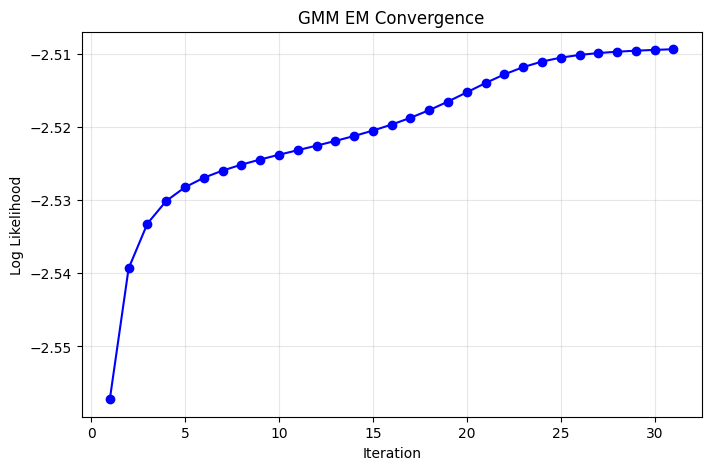

In [ ]:
# Plot likelihood history
history = []
gmm2 = GaussianMixture(n_components=3, covariance_type='full',
                       random_state=42, max_iter=1, warm_start=True)

for i in range(100):
    gmm2.fit(X_scaled)
    history.append(gmm2.lower_bound_)  # singular, this exists
    if len(history) > 1 and abs(history[-1] - history[-2]) < 1e-4:
        break

print(f"Converged in {len(history)} iterations")
print(f"Final Log-Likelihood: {history[-1]:.3f}")

plt.figure(figsize=(8,5))
plt.plot(range(1, len(history)+1), history, marker='o', color='blue')
plt.xlabel('Iteration')
plt.ylabel('Log Likelihood')
plt.title('GMM EM Convergence')
plt.grid(True, alpha=0.3)
plt.show()




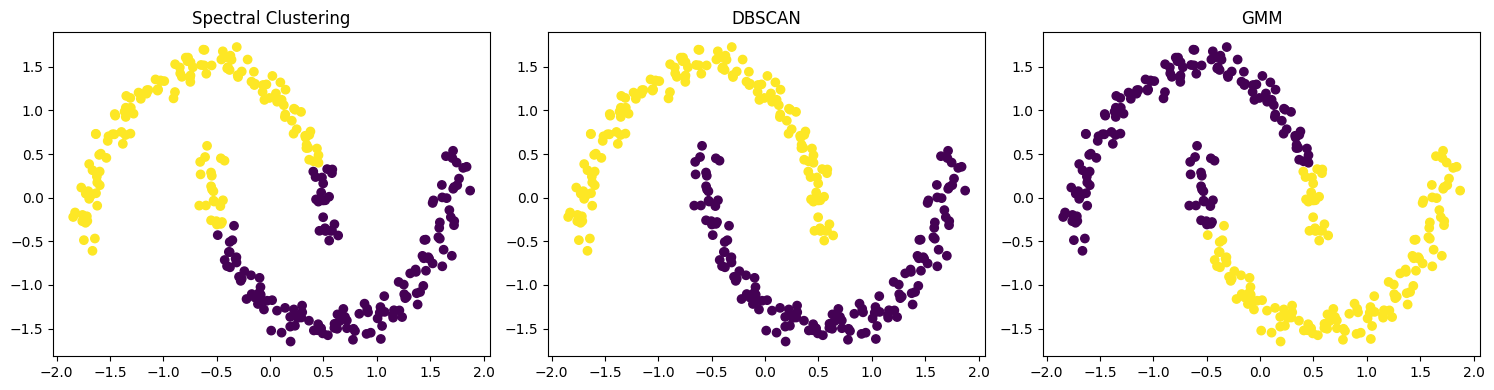

In [ ]:
# PART 11: COMPARING ALL THREE ALGORITHMS
# ============================================================

# Use one common dataset for comparison
X, y = make_moons(n_samples=300, noise=0.05, random_state=42)

X_scaled = StandardScaler().fit_transform(X)

# Spectral Clustering
spectral = SpectralClustering(
    n_clusters=2,
    affinity="rbf",
    gamma=0.5,
    random_state=42
)

spectral_labels = spectral.fit_predict(X_scaled)

# DBSCAN
dbscan = DBSCAN(eps=0.25, min_samples=5)

dbscan_labels = dbscan.fit_predict(X_scaled)

# GMM
gmm = GaussianMixture(
    n_components=2,
    reg_covar=1e-6,
    random_state=42
)

gmm_labels = gmm.fit_predict(X_scaled)

# Plot all three
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.scatter(X_scaled[:, 0], X_scaled[:, 1],
            c=spectral_labels)
plt.title("Spectral Clustering")

plt.subplot(1, 3, 2)
plt.scatter(X_scaled[:, 0], X_scaled[:, 1],
            c=dbscan_labels)
plt.title("DBSCAN")

plt.subplot(1, 3, 3)
plt.scatter(X_scaled[:, 0], X_scaled[:, 1],
            c=gmm_labels)
plt.title("GMM")

plt.tight_layout()
plt.show()